# Understanding Derivatives
The slope of a curve

**Goal:** To build an intuitive and programmatic understanding of the derivative. I will cover:
1. The concept of a derivative as an instantenous rate of change.
2. Visualizing the derivative as the slope of a tangent line.
3. Calculating derivates numerically using the limit definition.
4. Finding exact derivative formulas symbolically with SymPy.
5. Applying fundamental rules: the Power Rule and the Chain Rule.

## 1.: The Core Idea
From Average Slope to Instantaneous Slope

For a straight line, like $y = 2x + 1$, the slope is constant. For every step you take in $x$, $y$ increases by 2. The slope is always 2.
But what about a curve, like $f(x) = x^2$? The steepness of this function is constantly changing. It's very steep at x=10, but almost flat near $x=0$.

The **derivative** of a function at a specific point is the **slope of the curve at that exact point**.

To find that point, we can start by approximating it. We can pick two points on the curve and draw a straight line trough them. This is called a **secant line**. Its slope is the *average* rate of change between those two points.

The slope of a line between two points $(x1, y1)$ and $x2, y2$ is:
$$
slope = (y2-y1) / (x2 - x1)
$$

In our function notation, if we have a point $x$ and another point $x+h$ (where $h$ is a small change in $x$), the slope of the secant line is:
$$
\text{slope}_{\text{secant}}=\frac{f(x+h)-f(x)}{(x+h)-x}=\frac{f(x+h)-f(x)}{h}
$$

The core idea of calculus is: **what happens if we make $h$ incredibly, infinitesimally small?** As the second point slides along the curve closer and closer to the first, the secant line becomes a **tangent line**: a line that just touches the curve at that single point.
The slope of this tangent line is the derivative.

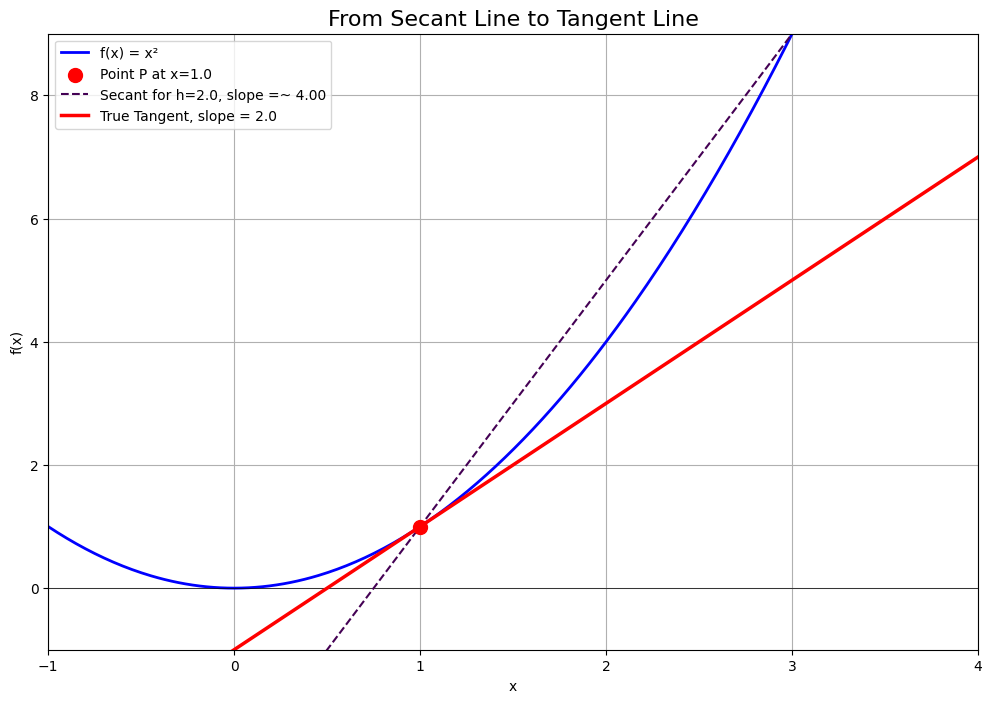

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Our function
def f(x):
    return x**2

# Our point x where we want to find the slope
x_point = 1.0

# Let's define a few values for 'h' (the distance to the second point)
# Starting with a large h and making it smaller
h_values = [2.0, 1.0, 0.5, 0.1, 0.01]

# Setup for plotting
x_range = np.linspace(-1, 4, 400)
y_range = f(x_range)

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(x_range, y_range, label="f(x) = x²", color='blue', linewidth=2)
ax.set_title("From Secant Line to Tangent Line", fontsize=16)
ax.grid(True)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(80, color='black', linewidth=0.5)

# Plot the point P where we are finding the slope
P = (x_point, f(x_point))
ax.scatter(*P, color='red', s=100, zorder=5, label=f"Point P at x={x_point}")

# Loop through our h_values to draw the secant lines
for i, h in enumerate(h_values):
    # Calculate the second point, Q
    Q = (x_point + h, f(x_point + h))

    # Calculate the slope of the secant line
    secant_slope = (Q[1] - P[1]) / (Q[0] - P[0])

    # Define the secant line function
    secant_line = lambda x: secant_slope * (x - P[0]) + P[1]

    # Plot the secant line
    line_color = plt.cm.viridis(i / len(h_values)) # gets a color gradient
    ax.plot(x_range, secant_line(x_range), linestyle='--', color=line_color,
        label=f"Secant for h={h}, slope =~ {secant_slope:.2f}")

    # The true tangent line (we know the derivative of x² is 2x, so at x=1, the slope is 2)
    tangent_slope = 2 * x_point
    tangent_line = lambda x: tangent_slope * (x - P[0]) + P[1]
    ax.plot(x_range, tangent_line(x_range), color='red', linewidth=2.5,
        label=f"True Tangent, slope = {tangent_slope}")

    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_ylim(-1, 9)
    ax.set_xlim(-1, 4)
    ax.legend()
    plt.show()

## 2.: Calculating the Derivative
The process just visualized is formalized by the **limit definition of the derivative**:
$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h})
$$
The notation $f'(x)$ (read "f prime of x") is one the common ways to write the derivate of $f(x)$

Let's turn this into a python function to compute the derivative numerically. We cant make $h$ truly zero, as that would cause a division by zero error, but we can make it a very small number, like $1\cdot10^{-7} \,\, (1\text{e}-7)$

The derivative of f(x)=x² at x=1 is approximately: 2.0000001010878066
The derivate of f(x)=x² at x=3 is approximately: 6.000000087880153
The derivative of g(x)=x³+2x at x=2 is approximately: 14.000000589931005
At x=1.0, the point is (1.00, 1.0) and the slope is 2.00
At x=3.0, the point is (3.00, 9.0) and the slope is 6.00
At x=2.0, the point is (2.00, 1.2e+01) and the slope is 14.00


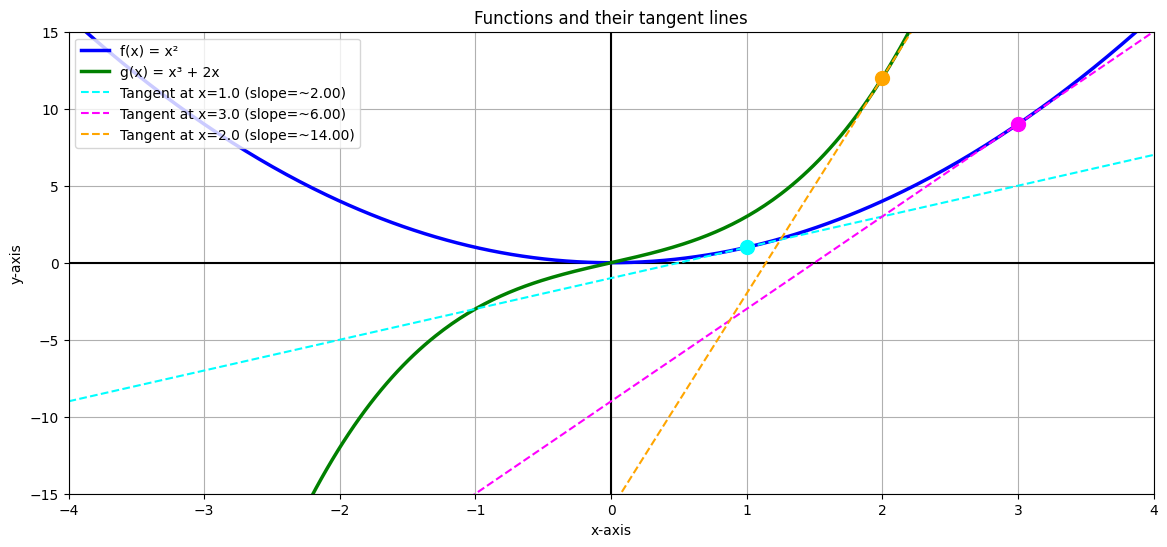

In [18]:
# 1. Our function f(x) = x²
def f1(x):
    return x**2

# 2. A more complex function g(x) = x³ + 2x
def f2(x):
    return x**3 + 2*x

def numerical_derivative(func, x, h=1e-7):
    """
    Calculates the numerical derivative of a function 'func' at point 'x'.

    Args:
        func (function): The function to differentiate
        x (float): The point at which to find the derivative
        h (float): A very small number to approximate the limit.

    Returns:
        The approximate slope of the tangent line at x.
    """
    return (func(x + h) - func(x)) / h

def plot_tangent(func, x_point, color='red'):
    """
    A helper function to calculate and plot the tangent line for a function at a given point.
    """
    # 1. Find the y-value at the point of tangency
    y_point = func(x_point)

    # 2. Calculate the slope (derivative) at that point)
    slope = numerical_derivative(func, x_point)
    print(f"At x={x_point}, the point is ({x_point:.2f}, {y_point:.2}) and the slope is {slope:.2f}")

    # 3. Define the tangent line using point-slope form: y = m(x - x1) + y1
    tangent_line = lambda x: slope * (x - x_point) + y_point

    # 4. Plot the point of tangency and the tangent line
    plt.scatter(x_point, y_point, color=color, s=100, zorder=5) # zorder=5 makes the dot appear on top
    plt.plot(x_values, tangent_line(x_values), color=color, linestyle='--',
             label=f"Tangent at x={x_point} (slope=~{slope:.2f})")

# Let's test it:

# Calculate derivative of f1(x) at x=1
deriv_at_1 = numerical_derivative(f1, 1)
print(f"The derivative of f(x)=x² at x=1 is approximately: {deriv_at_1}")

# Calculate derivate of f1(x) at x=3
deriv_at_3 = numerical_derivative(f1, 3)
print(f"The derivate of f(x)=x² at x=3 is approximately: {deriv_at_3}")

# Calculate derivate of f2(x) at x=2
deriv_f2_at_2 = numerical_derivative(f2, 2)
print(f"The derivative of g(x)=x³+2x at x=2 is approximately: {deriv_f2_at_2}")

# Define our plot
plt.figure(figsize=(14, 6))
plt.grid(True)
plt.axhline(0, color='black', linewidth=1.5) # x-achse
plt.axvline(0, color='black', linewidth=1.5) # y-achse
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.title("Functions and their tangent lines")

# generate x_values
x_values = np.linspace(-4, 4, 400)

# draw our functions
y1 = f1(x_values)
plt.plot(x_values, y1, label="f(x) = x²", color='blue', linewidth=2.5)

y2 = f2(x_values)
plt.plot(x_values, y2, label="g(x) = x³ + 2x", color='green', linewidth=2.5)

# --- Add the tanget lines

# For f(x) = x²
plot_tangent(f1, x_point=1.0, color='cyan')
plot_tangent(f1, x_point=3.0, color='magenta') # another one

# For g(x) = x³ + 2x
plot_tangent(f2, x_point=2.0, color='orange')

plt.xlim(-4, 4)
plt.ylim(-15, 15)

plt.legend(loc="upper left")
plt.show()